In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

matplotlib.rcParams['figure.dpi'] = 100

In [2]:
ROOT_DIR = Path("..").resolve()
PATH_CALIBRADOS = ROOT_DIR / "data" / "silver level" / "hsi_calibrado"

sample_path = list(PATH_CALIBRADOS.glob("*.npy"))[0]
cube_raw = np.load(sample_path)

cube_raw.shape

(291, 320, 256)

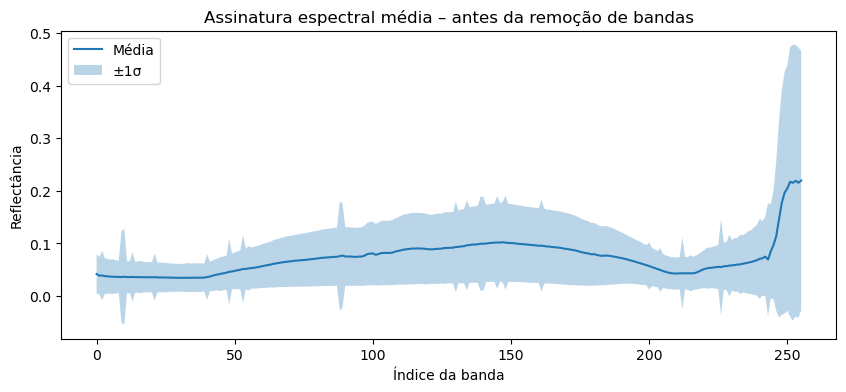

In [3]:
mean_raw = cube_raw.mean(axis=(0, 1))
std_raw = cube_raw.std(axis=(0, 1))

plt.figure(figsize=(10, 4))
plt.plot(mean_raw, label="Média")
plt.fill_between(
    range(len(mean_raw)),
    mean_raw - std_raw,
    mean_raw + std_raw,
    alpha=0.3,
    label="±1σ"
)
plt.title("Assinatura espectral média – antes da remoção de bandas")
plt.xlabel("Índice da banda")
plt.ylabel("Reflectância")
plt.legend()
plt.show()

In [4]:
bandas_inicio = 15
bandas_fim = 15

cube_cut = cube_raw[:, :, bandas_inicio:-bandas_fim]
cube_cut.shape

(291, 320, 226)

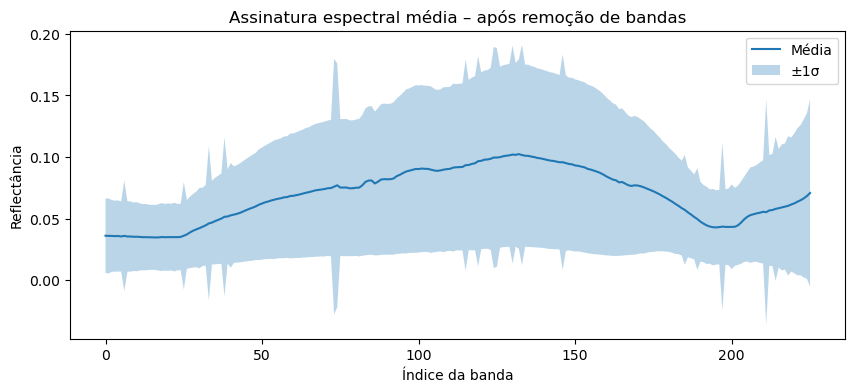

In [5]:
mean_cut = cube_cut.mean(axis=(0, 1))
std_cut = cube_cut.std(axis=(0, 1))

plt.figure(figsize=(10, 4))
plt.plot(mean_cut, label="Média")
plt.fill_between(
    range(len(mean_cut)),
    mean_cut - std_cut,
    mean_cut + std_cut,
    alpha=0.3,
    label="±1σ"
)
plt.title("Assinatura espectral média – após remoção de bandas")
plt.xlabel("Índice da banda")
plt.ylabel("Reflectância")
plt.legend()
plt.show()

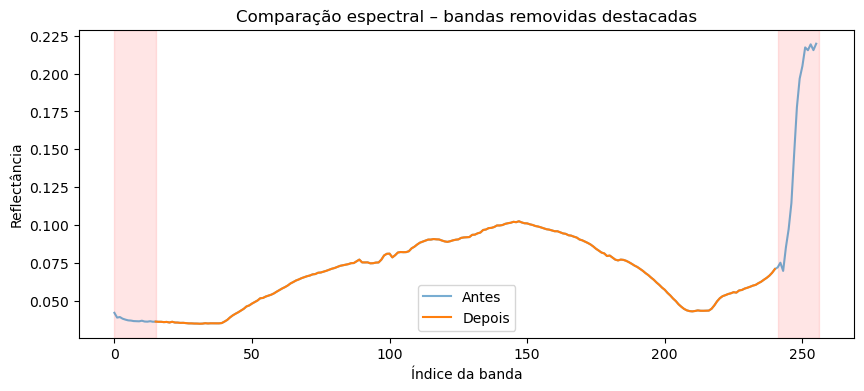

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(mean_raw, label="Antes", alpha=0.6)
plt.plot(
    range(bandas_inicio, len(mean_raw) - bandas_fim),
    mean_cut,
    label="Depois"
)
plt.axvspan(0, bandas_inicio, color="red", alpha=0.1)
plt.axvspan(len(mean_raw) - bandas_fim, len(mean_raw), color="red", alpha=0.1)
plt.title("Comparação espectral – bandas removidas destacadas")
plt.xlabel("Índice da banda")
plt.ylabel("Reflectância")
plt.legend()
plt.show()